# K-Nearest Neighbours (KNN)

**Idea:** to classify a new point, look at its `k` closest points in the training data and take a majority vote.

- No real "training" happens — the model just memorises the data (called a *lazy learner*).
- "Closest" is measured with **Euclidean distance**.
- We use the **Iris** dataset: 150 flowers, 4 measurements each, 3 species.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# load the dataset into a DataFrame so it is easy to look at
iris = load_iris()
df = pd.DataFrame(iris.data, columns=iris.feature_names)
df['species'] = iris.target   # 0 = setosa, 1 = versicolor, 2 = virginica

print(df.shape)
df.head()

(150, 5)


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0


In [2]:
# input features (X) and output label (y)
X = df.iloc[:, 0:4]
y = df['species']

# 80% for training, 20% for testing
# stratify=y keeps the same proportion of each species in both sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("train:", X_train.shape, "  test:", X_test.shape)

train: (120, 4)   test: (30, 4)


### Why scaling is important here

KNN works on **distance**. If one column has a much bigger range than the others, it dominates the distance and the small columns get ignored.

`StandardScaler` rescales every column to mean 0 and standard deviation 1, so all 4 features count equally.

Note: we `fit` the scaler on the **training data only**, then apply it to the test data. Fitting on test data would leak information.

In [3]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [4]:
# the actual model - just 2 lines
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train_scaled, y_train)

y_pred = knn.predict(X_test_scaled)

print("predicted:", y_pred)
print("actual   :", y_test.to_numpy())

predicted: [0 2 1 1 0 1 0 0 2 1 2 2 2 1 0 0 0 1 1 1 0 2 1 1 2 1 1 0 2 0]
actual   : [0 2 1 1 0 1 0 0 2 1 2 2 2 1 0 0 0 1 1 2 0 2 1 2 2 1 1 0 2 0]


In [5]:
# how good is it?
print("Accuracy:", accuracy_score(y_test, y_pred))
print()
print("Confusion matrix (rows = actual, columns = predicted):")
print(confusion_matrix(y_test, y_pred))
print()
print(classification_report(y_test, y_pred, target_names=iris.target_names))

Accuracy: 0.9333333333333333

Confusion matrix (rows = actual, columns = predicted):
[[10  0  0]
 [ 0 10  0]
 [ 0  2  8]]

              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.83      1.00      0.91        10
   virginica       1.00      0.80      0.89        10

    accuracy                           0.93        30
   macro avg       0.94      0.93      0.93        30
weighted avg       0.94      0.93      0.93        30



### Choosing k

`k` is the only real setting in KNN.

- **small k** (like 1) → very sensitive to noise / outliers (overfitting)
- **large k** → too smooth, starts ignoring local patterns (underfitting)

So we simply try several values and see which one scores best.

*Heads up: here we pick `k` by checking the test data, which is fine for learning but slightly cheating. The test set is only 30 flowers, so if it says the best k is 1, that is probably luck rather than proof — properly you would use cross-validation.*

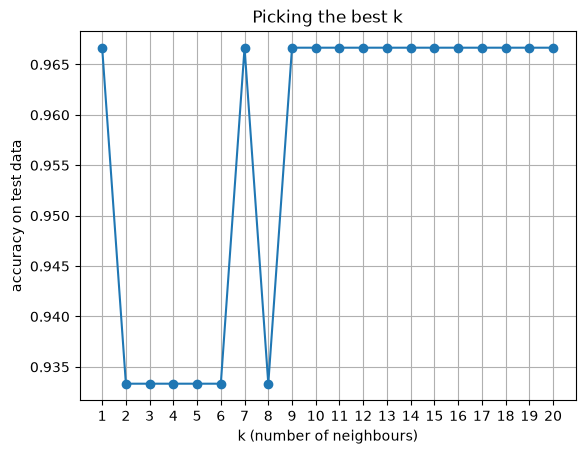

best k = 1  with accuracy 0.9666666666666667


In [6]:
k_values = range(1, 21)
scores = []

for k in k_values:
    model = KNeighborsClassifier(n_neighbors=k)
    model.fit(X_train_scaled, y_train)
    scores.append(accuracy_score(y_test, model.predict(X_test_scaled)))

plt.plot(k_values, scores, marker='o')
plt.xlabel("k (number of neighbours)")
plt.ylabel("accuracy on test data")
plt.title("Picking the best k")
plt.xticks(k_values)
plt.grid(True)
plt.show()

best_k = k_values[scores.index(max(scores))]
print("best k =", best_k, " with accuracy", max(scores))

In [7]:
# predict a brand new flower
# order of values: sepal length, sepal width, petal length, petal width (in cm)
new_flower = pd.DataFrame(
    [[5.1, 3.5, 1.4, 0.2]],
    columns=iris.feature_names
)

new_scaled = scaler.transform(new_flower)   # same scaling as training data
prediction = knn.predict(new_scaled)[0]

print("Predicted species:", iris.target_names[prediction])

# which 5 training points were the neighbours?
distances, indices = knn.kneighbors(new_scaled)
print("neighbour distances:", distances[0].round(3))
print("their species      :", iris.target_names[y_train.to_numpy()[indices[0]]])

Predicted species: setosa
neighbour distances: [0.    0.132 0.132 0.187 0.231]
their species      : ['setosa' 'setosa' 'setosa' 'setosa' 'setosa']
